<a href="https://colab.research.google.com/github/SalmaAnindhia/PemMes_25_Salma/blob/main/JS10/JS10_04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import cv2

from skimage.feature import hog
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras import layers, models

In [8]:
def load_dataset(img_dir):
    p = Path(img_dir)
    img_list = []
    for folder in p.glob('*'):
        label = folder.name
        for file in folder.glob('*.jpg'):
            img = cv2.imread(str(file))
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img_list.append((img, label))
    return img_list

train_dir = "/content/images/training/"
test_dir  = "/content/images/test/"

train_img = load_dataset(train_dir)
test_img  = load_dataset(test_dir)

# Cek: harus > 0
print("Jumlah data train:", len(train_img))
print("Jumlah data test :", len(test_img))

Jumlah data train: 240
Jumlah data test : 160


In [9]:
def resize_image(img, size=(256,256)):
    return cv2.resize(img, size)

def label_encoder(label):
    return 1 if label == 'day' else 0

def preprocess(img_list):
    X = []
    y = []
    for img, label in img_list:
        img_std = resize_image(img)
        X.append(img_std)
        y.append(label_encoder(label))
    return X, y

X_train_img, y_train = preprocess(train_img)
X_test_img,  y_test  = preprocess(test_img)

In [10]:
def extract_hog(X_imgs):
    feats = []
    for img in X_imgs:
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        hog_feat = hog(gray,
                       orientations=9,
                       pixels_per_cell=(8,8),
                       cells_per_block=(2,2),
                       block_norm='L2-Hys',
                       visualize=False,
                       feature_vector=True)
        feats.append(hog_feat)
    return np.array(feats)

X_train_feat = extract_hog(X_train_img)
X_test_feat  = extract_hog(X_test_img)

In [11]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_feat)
X_test_scaled  = scaler.transform(X_test_feat)

In [5]:
import os

# Cek isi folder kerja utama
print("Isi /content:", os.listdir("/content"))

# Cari semua file .jpg di seluruh sistem
jpg_files = []
for root, dirs, files in os.walk("/"):
    # skip folder sistem biar cepat
    if root.startswith(("/proc", "/sys", "/usr", "/opt")):
        continue
    for f in files:
        if f.lower().endswith(('.jpg', '.jpeg', '.png')):
            jpg_files.append(os.path.join(root, f))

print("Total gambar ditemukan:", len(jpg_files))
for f in jpg_files[:10]:   # tampilkan 10 pertama
    print(f)

Isi /content: ['.config', 'images', 'images.zip', '__MACOSX', 'sample_data']
Total gambar ditemukan: 2026
/root/.local/share/jupyter/kernels/julia/logo-64x64.png
/root/.local/share/jupyter/kernels/julia/logo-32x32.png
/root/.julia/artifacts/8e4faedde4bd75566bc8da1fccecb257eb6af6f2/share/doc/libogg/fish_xiph_org.png
/root/.julia/artifacts/8e4faedde4bd75566bc8da1fccecb257eb6af6f2/share/doc/libogg/pages.png
/root/.julia/artifacts/8e4faedde4bd75566bc8da1fccecb257eb6af6f2/share/doc/libogg/multiplex1.png
/root/.julia/artifacts/8e4faedde4bd75566bc8da1fccecb257eb6af6f2/share/doc/libogg/vorbisword2.png
/root/.julia/artifacts/8e4faedde4bd75566bc8da1fccecb257eb6af6f2/share/doc/libogg/packets.png
/root/.julia/artifacts/8e4faedde4bd75566bc8da1fccecb257eb6af6f2/share/doc/libogg/stream.png
/root/.julia/artifacts/8e4faedde4bd75566bc8da1fccecb257eb6af6f2/share/doc/libogg/white-xifish.png
/root/.julia/artifacts/8e4faedde4bd75566bc8da1fccecb257eb6af6f2/share/doc/libogg/white-ogg.png


In [4]:
!unzip images.zip -d /content/

Archive:  images.zip
   creating: /content/images/
  inflating: /content/__MACOSX/._images  
   creating: /content/images/test/
  inflating: /content/__MACOSX/images/._test  
   creating: /content/images/training/
  inflating: /content/__MACOSX/images/._training  
   creating: /content/images/test/day/
  inflating: /content/__MACOSX/images/test/._day  
   creating: /content/images/test/night/
  inflating: /content/__MACOSX/images/test/._night  
   creating: /content/images/training/day/
  inflating: /content/__MACOSX/images/training/._day  
   creating: /content/images/training/night/
  inflating: /content/__MACOSX/images/training/._night  
  inflating: /content/images/test/day/20151102_122322.jpg  
  inflating: /content/__MACOSX/images/test/day/._20151102_122322.jpg  
  inflating: /content/images/test/day/20151101_235039.jpg  
  inflating: /content/__MACOSX/images/test/day/._20151101_235039.jpg  
  inflating: /content/images/test/day/20151102_114041.jpg  
  inflating: /content/__MACOS

In [12]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_scaled, y_train,
    test_size=0.2,
    random_state=42
)

y_train = np.array(y_train)
y_val   = np.array(y_val)
y_test  = np.array(y_test)

In [13]:
input_dim = X_train.shape[1]

model = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │     4,428,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,436,737 (16.92 MB)

 Trainable params: 4,436,737 (16.92 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val)
)

Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 99ms/step - accuracy: 0.7969 - loss: 0.8805 - val_accuracy: 0.9375 - val_loss: 0.2761
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.9740 - loss: 0.1197 - val_accuracy: 1.0000 - val_loss: 1.7288e-07
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step - accuracy: 1.0000 - loss: 3.2459e-05 - val_accuracy: 1.0000 - val_loss: 4.9664e-08
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.9948 - loss: 0.0148 - val_accuracy: 1.0000 - val_loss: 4.0637e-08
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 1.0000 - loss: 1.6426e-06 - val_accuracy: 1.0000 - val_loss: 3.3457e-06
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 87ms/step - accuracy: 1.0000 - loss: 2.2453e-05 - val_accuracy: 1.0000 - val_loss: 5.7233e-05
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 97ms/step - accuracy: 1.0000 - loss: 5.3838e-04 - val_accuracy: 1.0000 - val_loss: 1.2288e-04
Epoch 8/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 99ms/step - accuracy: 1.0000 - loss: 3.7193e-0

In [15]:
test_loss, test_acc = model.evaluate(X_test_scaled, y_test)
print("Akurasi Test:", test_acc)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.8875 - loss: 2.2771
Akurasi Test: 0.887499988079071


In [16]:
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype(int)

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
              precision    recall  f1-score   support

           0       0.82      0.99      0.90        80
           1       0.98      0.79      0.88        80

    accuracy                           0.89       160
   macro avg       0.90      0.89      0.89       160
weighted avg       0.90      0.89      0.89       160

[[79  1]
 [17 63]]


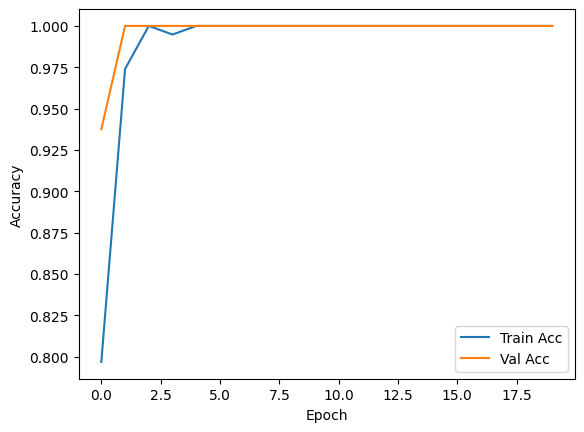

In [17]:
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [19]:
model.save('day_night_classifier_model.keras')